# **Logistic Regression Practice Notebook**

Dataset: **Titanic** (from the Seaborn library)

This notebook covers:
1. Univariate Logistic Regression
2. Multivariate Logistic Regression

Write your code in the empty cells below each question. Only a **Confusion Matrix** chart is required for each section — no other visualizations.

## **Section 1: Load and Prepare the Dataset**

**Q1.** Import the required libraries (`pandas`, `numpy`, `seaborn`, `matplotlib.pyplot`) and load the `titanic` dataset from Seaborn. Display the first 5 rows.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("titanic")

print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


**Q2.** Check the shape of the dataset, the data types of each column, and the count of missing values in each column.

In [2]:
print(df.shape)

print(df.dtypes)

print(df.isnull().sum())

(891, 15)
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


**Q3.** Handle the missing values in the dataset appropriately (choose suitable columns to drop or fill).

In [4]:
df=df.dropna()
df.shape
print(df.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
deck           0
embark_town    0
alive          0
alone          0
dtype: int64


**Q4.** Identify the target variable for this task (`survived`) and confirm it is binary (0/1).

In [5]:
y = df["survived"]

print(y.head())

print(y.unique())

print(y.value_counts())

1     1
3     1
6     0
10    1
11    1
Name: survived, dtype: int64
[1 0]
survived
1    123
0     59
Name: count, dtype: int64


## **Section 2: Univariate Logistic Regression**

Use a single feature (`fare`) to predict `survived`.

**Q5.** Define `X` using only the `fare` column and `y` using the `survived` column.

In [6]:
X_uni = df[["fare"]]

y_uni = df["survived"]

print(X_uni.head())

print(y_uni.head())

       fare
1   71.2833
3   53.1000
6   51.8625
10  16.7000
11  26.5500
1     1
3     1
6     0
10    1
11    1
Name: survived, dtype: int64


**Q6.** Split the data into training and testing sets.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_uni,
    y_uni,
    test_size=0.2,
    random_state=42,
    stratify=y_uni
)

print(X_train.shape)
print(X_test.shape)

(145, 1)
(37, 1)


**Q7.** Build a Logistic Regression model and train it on the training data.

In [8]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


**Q8.** Predict the `survived` outcome for the test set.

In [9]:
y_pred = model.predict(X_test)

print(y_pred)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


**Q9.** Calculate the accuracy of the model.

In [10]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 0.6756756756756757
Accuracy Percentage: 67.56756756756756


**Q10.** Print the model's coefficient and intercept.

In [11]:
print("Coefficient:", model.coef_)

print("Intercept:", model.intercept_)

Coefficient: [[0.00315785]]
Intercept: [0.49904717]


**Q11.** Plot the Confusion Matrix for the univariate model. (Only this chart is required for this section — no other visualizations.)

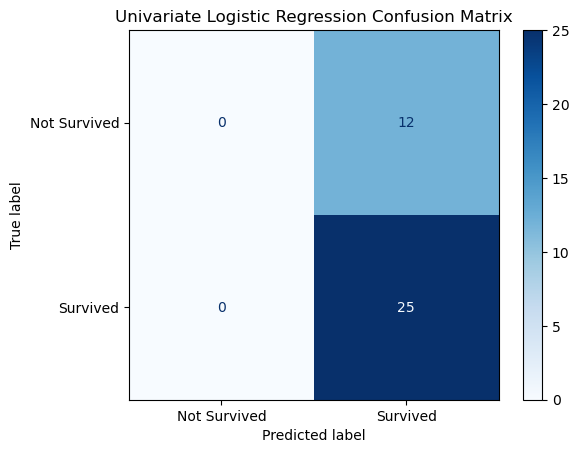

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Survived", "Survived"]
)

disp.plot(cmap="Blues")

plt.title("Univariate Logistic Regression Confusion Matrix")
plt.show()

## **Section 3: Multivariate Logistic Regression**

Use multiple features (`pclass`, `age`, `fare`, `sibsp`, `sex`) to predict `survived`.

**Q12.** Encode any categorical column(s) needed among the chosen features (e.g., `sex`) into numeric form.

In [15]:
df["sex_encoded"] = df["sex"].map({
    "male": 0,
    "female": 1
})

print(df[["sex", "sex_encoded"]].head())

       sex  sex_encoded
1   female            1
3   female            1
6     male            0
10  female            1
11  female            1


**Q13.** Define `X` using `pclass`, `age`, `fare`, `sibsp`, and the encoded `sex` column. Define `y` using `survived`.

In [16]:
X_multi = df[[
    "pclass",
    "age",
    "fare",
    "sibsp",
    "sex_encoded"
]]

y_multi = df["survived"]

print(X_multi.head())

print(y_multi.head())

    pclass   age     fare  sibsp  sex_encoded
1        1  38.0  71.2833      1            1
3        1  35.0  53.1000      1            1
6        1  54.0  51.8625      0            0
10       3   4.0  16.7000      1            1
11       1  58.0  26.5500      0            1
1     1
3     1
6     0
10    1
11    1
Name: survived, dtype: int64


**Q14.** Split the data into training and testing sets.

In [17]:
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi,
    y_multi,
    test_size=0.2,
    random_state=42,
    stratify=y_multi
)

print(X_train_multi.shape)

print(X_test_multi.shape)

(145, 5)
(37, 5)


**Q15.** Build a Logistic Regression model and train it on the training data.

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_multi)

X_test_scaled = scaler.transform(X_test_multi)

model_multi = LogisticRegression(max_iter=1000)

model_multi.fit(X_train_scaled, y_train_multi)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


**Q16.** Predict the `survived` outcome for the test set.

In [19]:
y_pred_multi = model_multi.predict(X_test_scaled)

print(y_pred_multi)

[1 0 0 1 1 1 1 1 1 1 0 1 1 1 1 1 0 1 0 1 1 1 0 0 0 1 1 1 0 1 1 0 1 1 1 1 1]


**Q17.** Calculate the accuracy of the model.

In [20]:
accuracy_multi = accuracy_score(y_test_multi, y_pred_multi)

print("Accuracy:", accuracy_multi)

print("Accuracy Percentage:", accuracy_multi * 100)

Accuracy: 0.7837837837837838
Accuracy Percentage: 78.37837837837837


**Q18.** Print the model's coefficients and intercept. Identify which feature has the strongest influence.

In [21]:
print("Coefficients:", model_multi.coef_)

print("Intercept:", model_multi.intercept_)

coef_df = pd.DataFrame({
    "Feature": X_multi.columns,
    "Coefficient": model_multi.coef_[0]
})

coef_df["Absolute Coefficient"] = coef_df["Coefficient"].abs()

print(coef_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
))

Coefficients: [[-0.38313772 -0.56485253 -0.08486467  0.05758637  1.20650107]]
Intercept: [1.06046677]
       Feature  Coefficient  Absolute Coefficient
4  sex_encoded     1.206501              1.206501
1          age    -0.564853              0.564853
0       pclass    -0.383138              0.383138
2         fare    -0.084865              0.084865
3        sibsp     0.057586              0.057586


**Q19.** Plot the Confusion Matrix for the multivariate model. (Only this chart is required for this section — no other visualizations.)

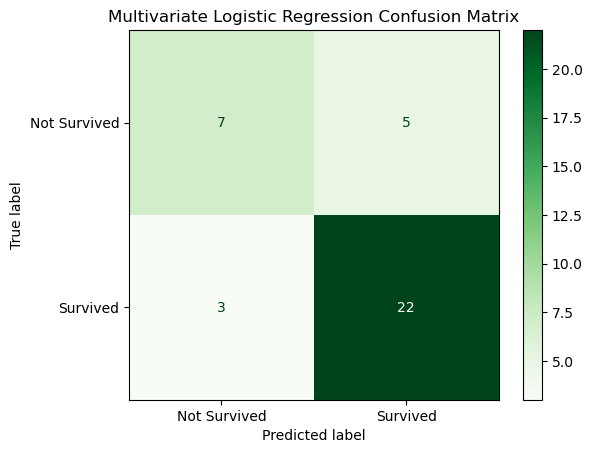

In [22]:
cm_multi = confusion_matrix(y_test_multi, y_pred_multi)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_multi,
    display_labels=["Not Survived", "Survived"]
)

disp.plot(cmap="Greens")

plt.title("Multivariate Logistic Regression Confusion Matrix")
plt.show()

**Q20.** Compare the accuracy of the univariate model (Section 2) with the multivariate model (Section 3). Which one performs better, and why do you think that is?

In [23]:
comparison = pd.DataFrame({
    "Model": ["Univariate Logistic Regression", "Multivariate Logistic Regression"],
    "Accuracy": [accuracy, accuracy_multi]
})

print(comparison)

if accuracy_multi > accuracy:
    print("Multivariate Logistic Regression performs better.")
elif accuracy > accuracy_multi:
    print("Univariate Logistic Regression performs better.")
else:
    print("Both models have the same accuracy.")

                              Model  Accuracy
0    Univariate Logistic Regression  0.675676
1  Multivariate Logistic Regression  0.783784
Multivariate Logistic Regression performs better.
